# Análisis de siniestros viales en Palmira, Colombia
**Fundamentos de Ciencia de Datos | Andrés Eduardo Barroso Velásquez**

## Propósito del proyecto
Analizar los registros de siniestros viales de Palmira y construir modelos de clasificación para diferenciar registros de víctimas con resultado **LESIONADO** o **MUERTO**.

**Pregunta de negocio:** ¿Qué características temporales, geográficas y del tipo de siniestro se asocian con el resultado registrado de las víctimas en Palmira?

**Utilidad:** describir patrones y generar evidencia exploratoria que pueda apoyar preguntas de seguridad vial y orientar análisis posteriores. El modelo no demuestra causalidad, no predice el futuro con certeza y no debe utilizarse para decisiones operativas o individuales.

## Fuente oficial del conjunto de datos
Portal Nacional de Datos Abiertos — **Siniestros Viales Palmira**:
https://www.datos.gov.co/w/sjpx-eqfp/dneh-mcp2

El resultado de búsqueda del portal identifica 2.834 filas y 19 columnas, con registros que incluyen los años 2022, 2023 y 2024.

## Metodología CRISP-DM
1. Comprensión del negocio.
2. Comprensión de los datos.
3. Preparación de los datos.
4. Modelado.
5. Evaluación.
6. Despliegue.



## 1. Preparación del entorno y lectura de datos


In [43]:

import os
import re
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ruta del archivo cargado desde Files de Google Colab
ruta_csv = "/content/Siniestros_Viales_Palmira_20261026.csv"

# Verificar que el archivo exista
if not os.path.exists(ruta_csv):
    raise FileNotFoundError(
        f"No se encontró el archivo: {ruta_csv}. "
        "Súbelo desde el panel Files de Google Colab."
    )

# Leer la base de datos
df_original = pd.read_csv(ruta_csv, low_memory=False)

print(f"Archivo: {os.path.basename(ruta_csv)}")
print(
    f"Dimensiones: {df_original.shape[0]:,} filas × "
    f"{df_original.shape[1]} columnas"
)

display(df_original.head())


Archivo: Siniestros_Viales_Palmira_20261026.csv
Dimensiones: 2,834 filas × 19 columnas


,AÑO,IPAT,CLASE SINIESTRO,FECHA,HORA,JORNADA,DIA_SEMANA,BARRIOS-CORREGIMIENTO- VIA,DIRECCION,ZONA,AUTORIDAD,LAT,LONG,HIPOTESIS,CODIGO,CONDICION DE LA VICTIMA,EDAD,GENERO,LESIONADOS Y MUERTOS
0,"2,022",8446.0,CHOQUE,2022-01-01,9:30,MAÑANA,SÁBADO,BARRIO NUEVO,CALLE 19 CARRERA 32,URBANA,TECNICO,"3,51833","-76,30400",IMPERICIA EN EL MANEJO,139.0,MOTOCICLISTA,22.0,MASCULINO,LESIONADO
1,"2,022",8446.0,CHOQUE,2022-01-01,9:30,MAÑANA,SÁBADO,BARRIO NUEVO,CALLE 19 CARRERA 32,URBANA,TECNICO,"3,51833","-76,30400",IMPERICIA EN EL MANEJO,139.0,MOTOCICLISTA,37.0,MASCULINO,LESIONADO
2,"2,022",8447.0,CHOQUE,2022-01-01,11:15,MAÑANA,SÁBADO,POBLADO COMFAUNION,CARRERA 18 CALLE 44,URBANA,TECNICO,"3,53869","-76,28967",NO RESPETAR PRELACIÓN,132.0,ACOMPAÑANTE MOTOCICLISTA,28.0,FEMENINO,LESIONADO
3,"2,022",8447.0,CHOQUE,2022-01-01,11:15,MAÑANA,SÁBADO,POBLADO COMFAUNION,CARRERA 18 CALLE 44,URBANA,TECNICO,"3,53869","-76,28967",NO RESPETAR PRELACIÓN,132.0,NO APLICA,31.0,MASCULINO,NO APLICA
4,"2,022",8447.0,CHOQUE,2022-01-01,11:15,MAÑANA,SÁBADO,POBLADO COMFAUNION,CARRERA 18 CALLE 44,URBANA,TECNICO,"3,53869","-76,28967",NO RESPETAR PRELACIÓN,132.0,MOTOCICLISTA,30.0,MASCULINO,LESIONADO


## 2. Comprensión del negocio y de los datos
El objetivo del análisis es comprender los patrones registrados en la base y estudiar si las variables disponibles permiten distinguir entre LESIONADO y MUERTO.

Antes de modelar, se verifica la estructura, los tipos de datos, los valores faltantes, las categorías y los duplicados. Las cifras descriptivas se calculan sobre el archivo efectivamente cargado; pueden variar si el portal actualiza el conjunto.

### ¿Qué revisamos aquí?
Esta revisión muestra qué información contiene la base, qué tipo de dato tiene cada columna y dónde faltan valores. También cuenta los registros repetidos. Esto ayuda a conocer la calidad de los datos antes de analizarlos.

In [44]:
print("Columnas y tipos:")
display(pd.DataFrame({"Variable": df_original.columns, "Tipo": df_original.dtypes.astype(str)}))

print("\nDimensiones:")
print(f"Filas: {len(df_original):,} | Columnas: {df_original.shape[1]}")

print("\nValores faltantes por variable:")
faltantes = df_original.isna().sum().sort_values(ascending=False)
display(faltantes.to_frame("Cantidad de faltantes"))

print("\nDuplicados exactos:", df_original.duplicated().sum())

print("\nEstadísticas descriptivas:")
display(df_original.describe(include="all").T)

Columnas y tipos:


,Variable,Tipo
AÑO,AÑO,object
IPAT,IPAT,object
CLASE SINIESTRO,CLASE SINIESTRO,object
FECHA,FECHA,object
HORA,HORA,object
JORNADA,JORNADA,object
DIA_SEMANA,DIA_SEMANA,object
BARRIOS-CORREGIMIENTO- VIA,BARRIOS-CORREGIMIENTO- VIA,object
DIRECCION,DIRECCION,object
ZONA,ZONA,object



Dimensiones:
Filas: 2,834 | Columnas: 19

Valores faltantes por variable:


,Cantidad de faltantes
LAT,10
CODIGO,10
LONG,10
CLASE SINIESTRO,0
IPAT,0
AÑO,0
FECHA,0
BARRIOS-CORREGIMIENTO- VIA,0
HORA,0
JORNADA,0



Duplicados exactos: 9

Estadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
AÑO,2834,3,"2,022",1786,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IPAT,2834,1148,DITRA,335,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLASE SINIESTRO,2834,18,CHOQUE,1970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FECHA,2834,642,2022-09-17,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HORA,2834,405,15:30,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN
JORNADA,2834,4,TARDE,1045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DIA_SEMANA,2834,7,DOMINGO,483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BARRIOS-CORREGIMIENTO- VIA,2834,196,CENTRO,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DIRECCION,2834,1114,CALLE 42 CARRERA 35,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZONA,2834,3,URBANA,2238,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Distribución inicial de la variable objetivo
Se examina `LESIONADOS Y MUERTOS`. Los registros `NO APLICA` y los valores vacíos no representan una de las dos clases del problema de clasificación y se excluyen del entrenamiento binario. Se conserva el conteo original para documentar esta decisión.

### ¿Qué muestran las gráficas?
Las gráficas permiten identificar cuáles años, jornadas, clases de siniestro e hipótesis aparecen con mayor frecuencia. Son una descripción de los registros disponibles y no significan por sí solas que una variable cause los accidentes.

LESIONADOS Y MUERTOS
LESIONADO    1722
NO APLICA     978
MUERTO        134
Name: count, dtype: int64


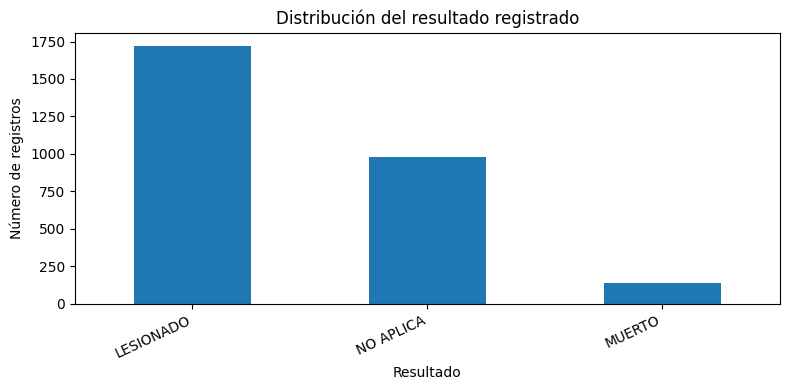

In [45]:
target_col = "LESIONADOS Y MUERTOS"
if target_col not in df_original.columns:
    raise KeyError(f"No se encontró la variable objetivo: {target_col}")

print(df_original[target_col].value_counts(dropna=False))
ax = df_original[target_col].value_counts(dropna=False).plot(kind="bar", figsize=(8,4))
ax.set_title("Distribución del resultado registrado")
ax.set_xlabel("Resultado")
ax.set_ylabel("Número de registros")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Exploración visual
Se presentan las distribuciones de año, jornada, clase de siniestro e hipótesis. Las gráficas describen frecuencias en los registros, no necesariamente cantidades de accidentes únicos.

### ¿Qué se hizo con los datos?
Se corrigieron formatos, se convirtieron edad y coordenadas a números y se quitaron únicamente los duplicados exactos. Para entrenar los modelos se conservaron los registros con resultado LESIONADO o MUERTO. Los valores extremos se revisan, pero no se borran automáticamente porque podrían ser datos válidos.

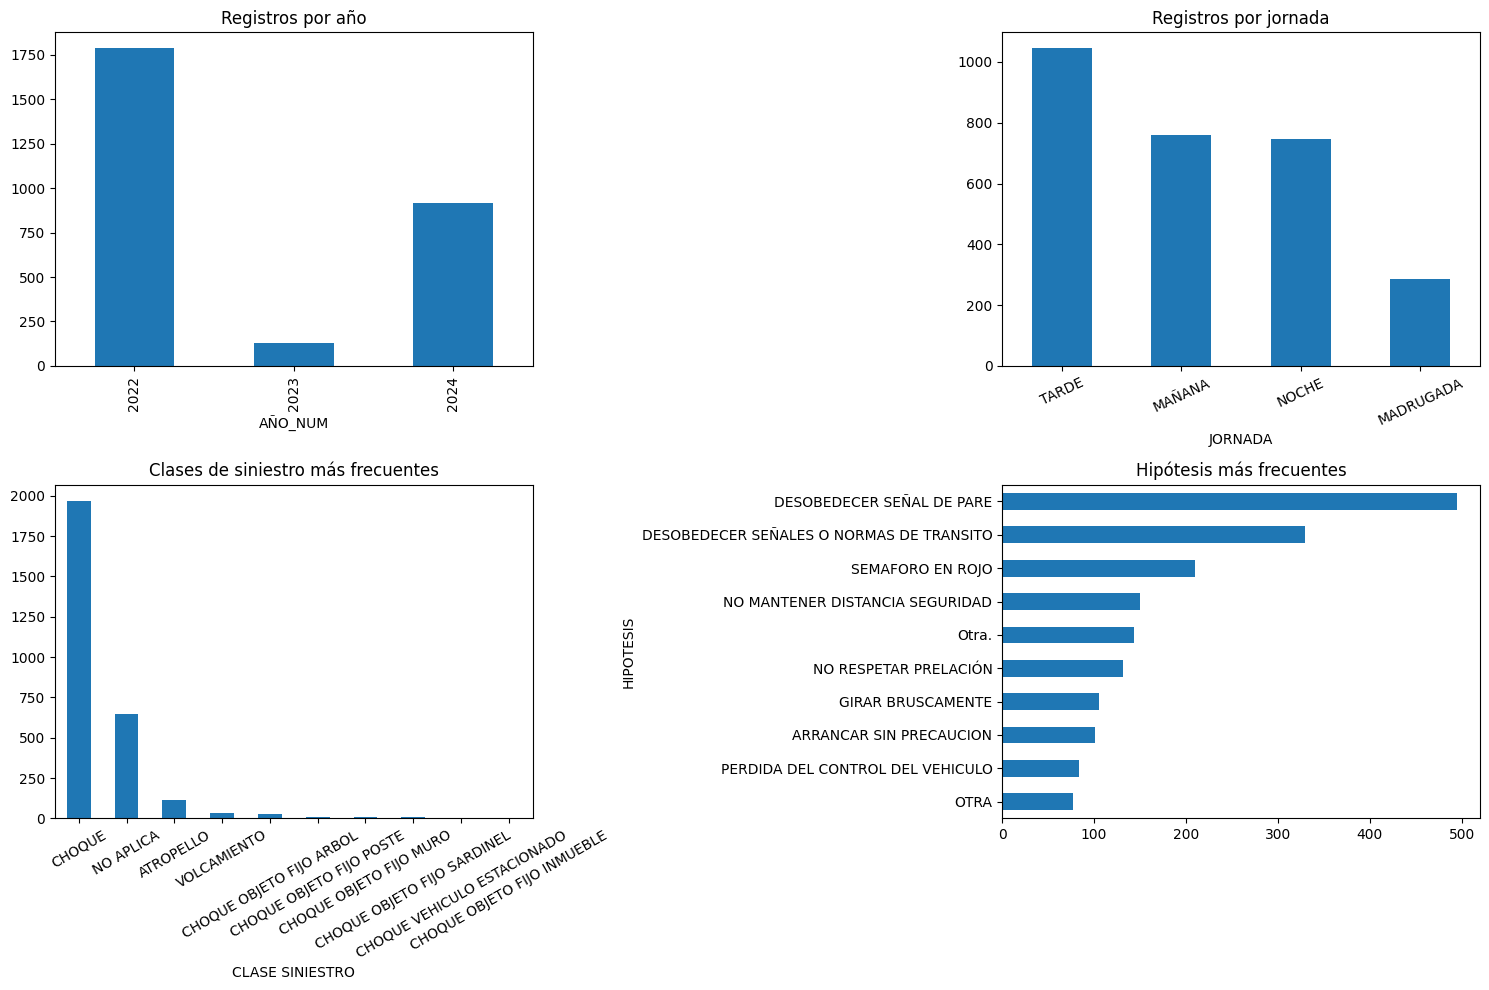

In [46]:
df = df_original.copy()
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

def to_numeric_flexible(s):
    s = s.astype("string").str.strip()
    s = s.replace({"NO APLICA": pd.NA, "": pd.NA, "nan": pd.NA})

    return pd.to_numeric(s.str.replace(",", ".", regex=False), errors="coerce")

if "AÑO" in df:
    df["AÑO_NUM"] = pd.to_numeric(
        df["AÑO"].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

fig, axes = plt.subplots(2, 2, figsize=(15,10))
if "AÑO_NUM" in df:
    df["AÑO_NUM"].value_counts().sort_index().plot(kind="bar", ax=axes[0,0])
    axes[0,0].set_title("Registros por año")
if "JORNADA" in df:
    df["JORNADA"].value_counts().plot(kind="bar", ax=axes[0,1])
    axes[0,1].set_title("Registros por jornada")
    axes[0,1].tick_params(axis="x", rotation=25)
if "CLASE SINIESTRO" in df:
    df["CLASE SINIESTRO"].value_counts().head(10).plot(kind="bar", ax=axes[1,0])
    axes[1,0].set_title("Clases de siniestro más frecuentes")
    axes[1,0].tick_params(axis="x", rotation=30)
if "HIPOTESIS" in df:
    df["HIPOTESIS"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[1,1])
    axes[1,1].set_title("Hipótesis más frecuentes")
plt.tight_layout()
plt.show()

## 3. Limpieza y preparación de datos
- Normalizar espacios y cadenas vacías.
- Convertir edad y coordenadas a valores numéricos; las comas decimales se convierten a puntos.
- Convertir año a numérico.
- Eliminar duplicados exactos y registrar cuántos se eliminan.
- Excluir del modelado los registros sin etiqueta o con `NO APLICA`.
- No eliminar automáticamente outliers: primero se identifican y se evalúa si son errores o valores extremos plausibles.
- Imputar valores faltantes dentro del pipeline, ajustando la imputación solo con los datos de entrenamiento.

### ¿Por qué se eligen estas variables?
Se utilizan variables relacionadas con el tiempo, el lugar y las características registradas del siniestro o de la víctima. El identificador IPAT no se entrega al modelo: solo sirve para mantener juntas las filas del mismo siniestro y evitar que información relacionada quede a la vez en entrenamiento y prueba.

In [47]:
#Conversiones de variables numéricas
for col in ["EDAD", "LAT", "LONG"]:
    if col in df:
        df[col + "_NUM"] = to_numeric_flexible(df[col])

if "AÑO" in df:
    df["AÑO_NUM"] = pd.to_numeric(
        df["AÑO"].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

#Duplicados exactos
n_antes = len(df)
df = df.drop_duplicates().copy()
print("Duplicados exactos eliminados:", n_antes - len(df))

#Revisiones básicas de edad y coordenadas
if "EDAD_NUM" in df:
    edades_invalidas = df[(df["EDAD_NUM"] < 0) | (df["EDAD_NUM"] > 110)]
    print("Edades fuera del rango de revisión (0-110):", len(edades_invalidas))

if "LAT_NUM" in df and "LONG_NUM" in df:
    coords_invalidas = df[
        ~df["LAT_NUM"].between(-5, 15) |
        ~df["LONG_NUM"].between(-85, -65)
    ]
    print("Coordenadas fuera de un rango amplio de Colombia (revisar):", len(coords_invalidas))

#Distribución válida para clasificación
df_model = df[df[target_col].isin(["LESIONADO", "MUERTO"])].copy()
df_model["OBJETIVO"] = df_model[target_col].astype(str)

print("\nRegistros disponibles para modelado:", len(df_model))
display(df_model["OBJETIVO"].value_counts().to_frame("Cantidad"))
display((df_model["OBJETIVO"].value_counts(normalize=True)*100).round(2).to_frame("Porcentaje"))

Duplicados exactos eliminados: 9
Edades fuera del rango de revisión (0-110): 0
Coordenadas fuera de un rango amplio de Colombia (revisar): 1

Registros disponibles para modelado: 1851


,Cantidad
OBJETIVO,
LESIONADO,1717
MUERTO,134


,Porcentaje
OBJETIVO,
LESIONADO,92.76
MUERTO,7.24


### Detección de valores atípicos (IQR)
Se utiliza el rango intercuartílico (IQR) como método de detección exploratoria para edad y coordenadas. En variables geográficas, los valores extremos deben interpretarse espacialmente; no se eliminan automáticamente. La edad también debe contrastarse con el diccionario y el contexto del registro.

### ¿Por qué se separan los datos por IPAT?
Una parte de los registros se usa para entrenar y otra para comprobar el desempeño. La separación por IPAT evita que víctimas del mismo siniestro aparezcan en ambos grupos. Esto hace que la evaluación sea más justa y reduce el riesgo de que el modelo memorice información de un mismo evento.

In [48]:
columnas_outliers = [c for c in ["EDAD_NUM", "LAT_NUM", "LONG_NUM"] if c in df_model.columns]
resumen_outliers = []

for col in columnas_outliers:
    serie = df_model[col].dropna()
    if len(serie) == 0:
        continue
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    cantidad = ((serie < inferior) | (serie > superior)).sum()
    resumen_outliers.append({
        "Variable": col, "Q1": q1, "Q3": q3,
        "Límite inferior": inferior, "Límite superior": superior,
        "Outliers detectados": int(cantidad)
    })

display(pd.DataFrame(resumen_outliers))

,Variable,Q1,Q3,Límite inferior,Límite superior,Outliers detectados
0,EDAD_NUM,23.00000,45.000000,-10.000000,78.000000,21
1,LAT_NUM,3.52213,3.538610,3.497410,3.563330,257
2,LONG_NUM,-76.31140,-76.293553,-76.338171,-76.266781,298


### ¿Qué hacen los tres modelos?
- **Regresión logística:** calcula qué tan probable es que un registro pertenezca a cada clase.
- **Árbol de decisión:** toma decisiones mediante reglas y condiciones.
- **Random Forest:** combina varios árboles para producir una clasificación.

El preprocesamiento completa datos faltantes y convierte las categorías en valores que los modelos pueden utilizar. La búsqueda prueba diferentes configuraciones.

## 4. Selección de variables y prevención de fuga de información
Se excluyen:
- `LESIONADOS Y MUERTOS` y `OBJETIVO`, porque constituyen la etiqueta que se desea predecir.
- `IPAT`, porque es un identificador; se conserva únicamente para agrupar los registros del mismo siniestro durante la separación de datos.
- `DIRECCION` y `CODIGO`, para evitar usar dirección exacta o códigos cuyo significado no se ha documentado en este notebook.
- `FECHA` como texto original; se usa `AÑO_NUM` y las variables temporales categóricas disponibles.

`CONDICION DE LA VICTIMA` se interpreta en el conjunto como el tipo/rol del actor vial (por ejemplo, motociclista o acompañante), no como la gravedad del resultado. Si el diccionario oficial de la versión descargada define esta columna de otra manera, debe revisarse antes de mantenerla como predictor.

### ¿Cómo se interpreta la evaluación?
La validación cruzada calcula el desempeño en varias particiones del conjunto de entrenamiento. Se selecciona el modelo con el mayor F1 para la clase MUERTO. Después, el conjunto de prueba se utiliza para medir el resultado final, sin intervenir en la selección. La precisión indica cuántas predicciones MUERTO fueron correctas; el recall indica cuántos casos MUERTO logró detectar; el F1 combina ambas medidas.

In [49]:
candidatas = [
    "AÑO_NUM", "HORA", "JORNADA", "DIA_SEMANA",
    "CLASE SINIESTRO", "ZONA", "AUTORIDAD", "HIPOTESIS",
    "CONDICION DE LA VICTIMA", "EDAD_NUM", "GENERO",
    "LAT_NUM", "LONG_NUM", "BARRIOS-CORREGIMIENTO- VIA"
]
features = [c for c in candidatas if c in df_model.columns]

if "IPAT" not in df_model.columns:
    raise KeyError("No existe IPAT. Se requiere revisar cómo identificar registros del mismo siniestro antes de separar entrenamiento y prueba.")

# Se excluyen grupos sin identificador válido del análisis de modelado
df_model = df_model[df_model["IPAT"].notna()].copy()
X = df_model[features].copy()
y = df_model["OBJETIVO"].copy()
groups = df_model["IPAT"].astype(str).copy()

num_cols = [c for c in X.columns if c.endswith("_NUM")]
cat_cols = [c for c in X.columns if c not in num_cols]

for c in num_cols:
    X[c] = pd.to_numeric(X[c], errors="coerce")
for c in cat_cols:
    X[c] = X[c].astype(object).where(X[c].notna(), np.nan)

print("Variables predictoras:", features)
print("Variables numéricas:", num_cols)
print("Variables categóricas:", cat_cols)
print("Número de IPAT/grupos:", groups.nunique())
display(X.head())

Variables predictoras: ['AÑO_NUM', 'HORA', 'JORNADA', 'DIA_SEMANA', 'CLASE SINIESTRO', 'ZONA', 'AUTORIDAD', 'HIPOTESIS', 'CONDICION DE LA VICTIMA', 'EDAD_NUM', 'GENERO', 'LAT_NUM', 'LONG_NUM', 'BARRIOS-CORREGIMIENTO- VIA']
Variables numéricas: ['AÑO_NUM', 'EDAD_NUM', 'LAT_NUM', 'LONG_NUM']
Variables categóricas: ['HORA', 'JORNADA', 'DIA_SEMANA', 'CLASE SINIESTRO', 'ZONA', 'AUTORIDAD', 'HIPOTESIS', 'CONDICION DE LA VICTIMA', 'GENERO', 'BARRIOS-CORREGIMIENTO- VIA']
Número de IPAT/grupos: 1009


,AÑO_NUM,HORA,JORNADA,DIA_SEMANA,CLASE SINIESTRO,ZONA,AUTORIDAD,HIPOTESIS,CONDICION DE LA VICTIMA,EDAD_NUM,GENERO,LAT_NUM,LONG_NUM,BARRIOS-CORREGIMIENTO- VIA
0,2022,9:30,MAÑANA,SÁBADO,CHOQUE,URBANA,TECNICO,IMPERICIA EN EL MANEJO,MOTOCICLISTA,22.0,MASCULINO,3.51833,-76.304,BARRIO NUEVO
1,2022,9:30,MAÑANA,SÁBADO,CHOQUE,URBANA,TECNICO,IMPERICIA EN EL MANEJO,MOTOCICLISTA,37.0,MASCULINO,3.51833,-76.304,BARRIO NUEVO
2,2022,11:15,MAÑANA,SÁBADO,CHOQUE,URBANA,TECNICO,NO RESPETAR PRELACIÓN,ACOMPAÑANTE MOTOCICLISTA,28.0,FEMENINO,3.53869,-76.28967,POBLADO COMFAUNION
4,2022,11:15,MAÑANA,SÁBADO,CHOQUE,URBANA,TECNICO,NO RESPETAR PRELACIÓN,MOTOCICLISTA,30.0,MASCULINO,3.53869,-76.28967,POBLADO COMFAUNION
5,2022,13:10,TARDE,SÁBADO,CHOQUE,URBANA,TECNICO,SEMAFORO EN ROJO,MOTOCICLISTA,19.0,MASCULINO,3.52657,-76.30258,CENTRO


## 5. División de entrenamiento y prueba por siniestro
Como varias filas pueden pertenecer al mismo `IPAT`, se utiliza `StratifiedGroupKFold`. Así se evita que víctimas de un mismo siniestro aparezcan simultáneamente en entrenamiento y prueba. Se verifica que ambas clases estén representadas y que no haya grupos compartidos.

### ¿Para qué se guarda el modelo?
Se exporta el preprocesamiento junto con el modelo seleccionado y los datos necesarios para construir el formulario de Streamlit. La aplicación debe utilizar este archivo y versiones compatibles de las bibliotecas.

In [50]:
from sklearn.model_selection import StratifiedGroupKFold

cv_holdout = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(cv_holdout.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))
print("\nDistribución entrenamiento:")
display(y_train.value_counts(normalize=True).mul(100).round(2).to_frame("Porcentaje"))
print("\nDistribución prueba:")
display(y_test.value_counts(normalize=True).mul(100).round(2).to_frame("Porcentaje"))
print("\nGrupos compartidos entre entrenamiento y prueba:", len(set(groups_train) & set(groups_test)))

if y_train.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError("La partición no contiene ambas clases en entrenamiento y prueba. Revisar grupos y estrategia de partición.")

Entrenamiento: 1196 | Prueba: 655

Distribución entrenamiento:


,Porcentaje
OBJETIVO,
LESIONADO,95.23
MUERTO,4.77



Distribución prueba:


,Porcentaje
OBJETIVO,
LESIONADO,88.24
MUERTO,11.76



Grupos compartidos entre entrenamiento y prueba: 0


## 6. Modelado: tres algoritmos y ajuste de hiperparámetros
Se comparan regresión logística, árbol de decisión y Random Forest. Los pasos de imputación, escalado y codificación forman parte del pipeline para evitar que la información del conjunto de prueba influya en el preprocesamiento.

La búsqueda de hiperparámetros se realiza únicamente dentro del conjunto de entrenamiento y utiliza validación cruzada estratificada por grupos. La métrica de búsqueda es F1 para la clase `MUERTO`; la evaluación final se realiza una sola vez sobre el conjunto de prueba.

In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, ParameterGrid
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    make_scorer
)

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

cv_model = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
scorer_muerto = make_scorer(f1_score, pos_label="MUERTO", zero_division=0)

configuraciones = {
    "Regresión logística": (
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42),
        {"model__C": [0.1, 0.5, 1, 2, 5, 10]}
    ),
    "Árbol de decisión": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"model__max_depth": [3, 5, 8, 12, None],
         "model__min_samples_leaf": [2, 5, 10, 15]}
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=1),
        {"model__n_estimators": [200, 300, 500],
         "model__max_depth": [None, 8, 12, 18],
         "model__min_samples_leaf": [2, 4, 8],
         "model__max_features": ["sqrt", 0.7]}
    )
}

busquedas = {}
resultados = []

for nombre, (estimador, parametros) in configuraciones.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimador)
    ])

    iteraciones = min(8, len(list(ParameterGrid(parametros))))
    busqueda = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=parametros,
        n_iter=iteraciones,
        scoring=scorer_muerto,
        cv=cv_model,
        random_state=42,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )
    busqueda.fit(X_train, y_train, groups=groups_train)
    busquedas[nombre] = busqueda

    pred = busqueda.best_estimator_.predict(X_test)
    resultados.append({
        "Modelo": nombre,
        "F1 CV (MUERTO)": busqueda.best_score_,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (MUERTO)": precision_score(y_test, pred, pos_label="MUERTO", zero_division=0),
        "Recall (MUERTO)": recall_score(y_test, pred, pos_label="MUERTO", zero_division=0),
        "F1 (MUERTO)": f1_score(y_test, pred, pos_label="MUERTO", zero_division=0),
        "F1 macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })
    print(f"{nombre} — mejores parámetros: {busqueda.best_params_}")

#La selección se basa únicamente en la validación cruzada del entrenamiento.
#Las métricas del conjunto de prueba se reservan para la evaluación final.
tabla_resultados = pd.DataFrame(resultados).sort_values(
    "F1 CV (MUERTO)",
    ascending=False
).reset_index(drop=True)

display(tabla_resultados.round(3))

Regresión logística — mejores parámetros: {'model__C': 0.5}
Árbol de decisión — mejores parámetros: {'model__min_samples_leaf': 5, 'model__max_depth': 5}
Random Forest — mejores parámetros: {'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}


,Modelo,F1 CV (MUERTO),Accuracy,Precision (MUERTO),Recall (MUERTO),F1 (MUERTO),F1 macro
0,Random Forest,0.310,0.591,0.197,0.805,0.316,0.512
1,Regresión logística,0.291,0.666,0.225,0.753,0.346,0.561
2,Árbol de decisión,0.225,0.670,0.144,0.364,0.206,0.499


## 7. Evaluación y selección del modelo
Se prioriza el F1 de la clase `MUERTO`, seguido del Recall y del F1 macro. Accuracy se informa, pero no es suficiente cuando las clases están desbalanceadas.

La matriz de confusión permite identificar falsos negativos: víctimas registradas como `MUERTO` que el modelo clasifica como `LESIONADO`. La precisión baja significa que puede haber bastantes falsas alarmas; por tanto, el modelo se considera experimental y no apto para decisiones reales sin validación adicional.

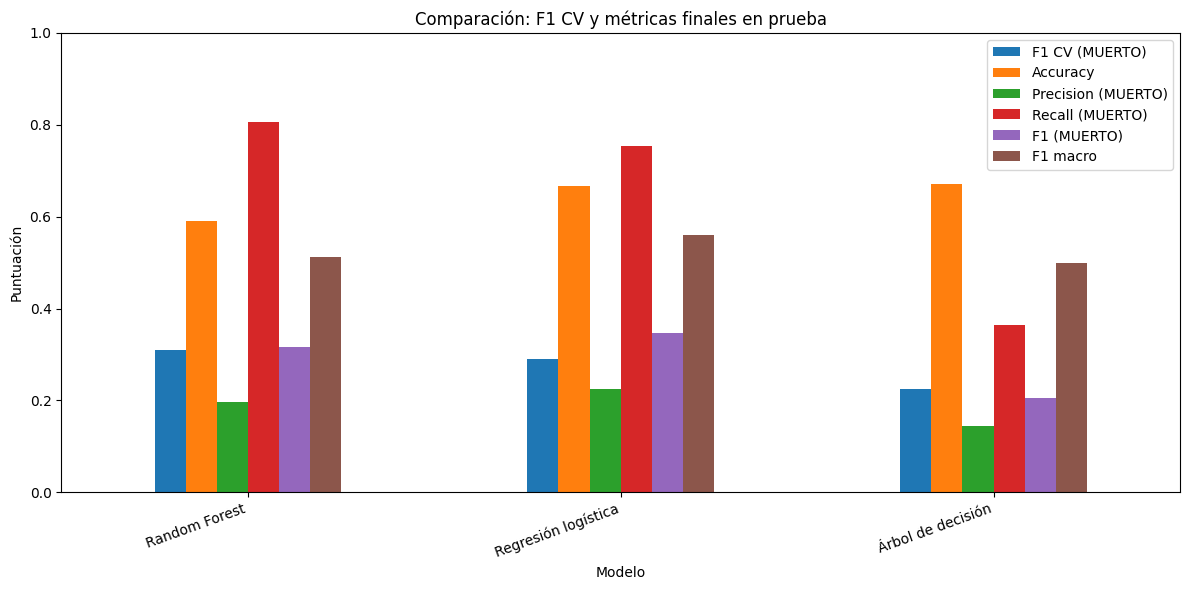

Modelo seleccionado por mayor F1 CV (MUERTO): Random Forest
La selección se hizo con validación cruzada del entrenamiento; las métricas de prueba solo se usan para evaluar el resultado final.

Reporte de clasificación:
              precision    recall  f1-score   support

   LESIONADO       0.96      0.56      0.71       578
      MUERTO       0.20      0.81      0.32        77

    accuracy                           0.59       655
   macro avg       0.58      0.68      0.51       655
weighted avg       0.87      0.59      0.66       655



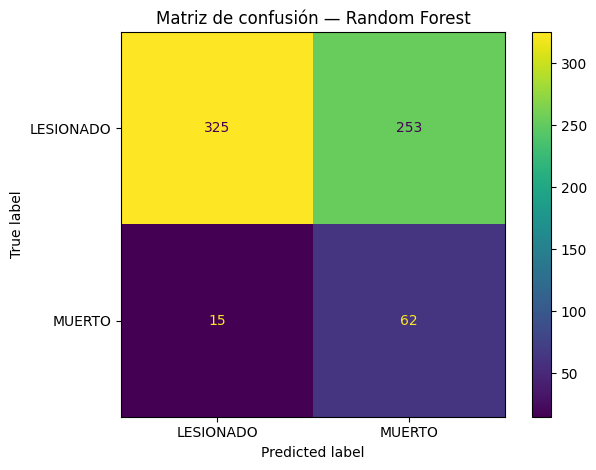

Mejores parámetros: {'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}


In [52]:
metricas = ["F1 CV (MUERTO)", "Accuracy", "Precision (MUERTO)", "Recall (MUERTO)", "F1 (MUERTO)", "F1 macro"]
tabla_resultados.set_index("Modelo")[metricas].plot(kind="bar", figsize=(12,6))
plt.title("Comparación: F1 CV y métricas finales en prueba")
plt.ylabel("Puntuación")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

mejor_nombre = tabla_resultados.iloc[0]["Modelo"]
mejor_modelo = busquedas[mejor_nombre].best_estimator_
pred_mejor = mejor_modelo.predict(X_test)

print("Modelo seleccionado por mayor F1 CV (MUERTO):", mejor_nombre)
print("La selección se hizo con validación cruzada del entrenamiento; las métricas de prueba solo se usan para evaluar el resultado final.")
print("\nReporte de clasificación:")
print(classification_report(y_test, pred_mejor, labels=["LESIONADO", "MUERTO"], zero_division=0))

cm = confusion_matrix(y_test, pred_mejor, labels=["LESIONADO", "MUERTO"])
ConfusionMatrixDisplay(cm, display_labels=["LESIONADO", "MUERTO"]).plot(values_format="d")
plt.title(f"Matriz de confusión — {mejor_nombre}")
plt.tight_layout()
plt.show()

print("Mejores parámetros:", busquedas[mejor_nombre].best_params_)

### Interpretación automática de resultados
La siguiente celda genera cifras reales a partir de la ejecución.

In [53]:
fila = tabla_resultados.iloc[0]
print(f"El modelo seleccionado fue {fila['Modelo']}.")
print(f"Accuracy: {fila['Accuracy']:.3f}")
print(f"Precision para MUERTO: {fila['Precision (MUERTO)']:.3f}")
print(f"Recall para MUERTO: {fila['Recall (MUERTO)']:.3f}")
print(f"F1 para MUERTO: {fila['F1 (MUERTO)']:.3f}")
print(f"F1 macro: {fila['F1 macro']:.3f}")
print("\nLa selección prioriza F1 de MUERTO, luego Recall y F1 macro.")

El modelo seleccionado fue Random Forest.
Accuracy: 0.591
Precision para MUERTO: 0.197
Recall para MUERTO: 0.805
F1 para MUERTO: 0.316
F1 macro: 0.512

La selección prioriza F1 de MUERTO, luego Recall y F1 macro.


In [54]:
# Jornada más frecuente
display(df["JORNADA"].value_counts())

# Clase de siniestro más frecuente
display(df["CLASE SINIESTRO"].value_counts())

# Hipótesis más frecuente
display(df["HIPOTESIS"].value_counts())

# Zona más frecuente
display(df["ZONA"].value_counts())

,count
JORNADA,
TARDE,1043
MAÑANA,755
NOCHE,742
MADRUGADA,285


,count
CLASE SINIESTRO,
CHOQUE,1963
NO APLICA,645
ATROPELLO,114
VOLCAMIENTO,34
CHOQUE OBJETO FIJO ARBOL,30
CHOQUE OBJETO FIJO POSTE,8
CHOQUE OBJETO FIJO MURO,7
CHOQUE OBJETO FIJO SARDINEL,6
CHOQUE VEHICULO ESTACIONADO,4


,count
HIPOTESIS,
DESOBEDECER SEÑAL DE PARE,494
DESOBEDECER SEÑALES O NORMAS DE TRANSITO,329
SEMAFORO EN ROJO,210
NO MANTENER DISTANCIA SEGURIDAD,150
Otra.,142
...,...
FALTA DE PERICIA,1
TRANSPORTE DE CARGA SIN SEGURIDAD,1
CONDUCIR EN ESTADO DE EMBRIAGUEZ,1


,count
ZONA,
URBANA,2229
RURAL,581
NACIONAL,15


## 8. Despliegue: exportar el pipeline y los metadatos para Streamlit
Se guarda el pipeline completo, incluyendo imputación, escalado, codificación y modelo. También se guardan las columnas esperadas, tipos y valores de referencia para construir un formulario en `app.py`.

El archivo `.joblib` contiene objetos Python serializados.

In [55]:

#Opciones y valores iniciales para el formulario Streamlit
metadata_app = {
    "features": features,
    "numeric_cols": num_cols,
    "categorical_cols": cat_cols,
    "numeric_defaults": {
        c: float(X_train[c].median()) if X_train[c].notna().any() else 0.0
        for c in num_cols
    },
    "categorical_options": {
        c: sorted(X_train[c].dropna().astype(str).unique().tolist())[:100]
        for c in cat_cols
    }
}

#Crear el artefacto del modelo
artefacto = {
    "model": mejor_modelo,
    "metadata": metadata_app,
    "selected_model": mejor_nombre,
    "source": "datos.gov.co — Siniestros Viales Palmira",
    "target_classes": ["LESIONADO", "MUERTO"]
}


model_path = "/content/modelo_siniestros_palmira.joblib"

joblib.dump(artefacto, model_path)

print("Modelo guardado correctamente:", model_path)
print("Modelo seleccionado:", mejor_nombre)


from google.colab import files
files.download(model_path)


Modelo guardado correctamente: /content/modelo_siniestros_palmira.joblib
Modelo seleccionado: Random Forest


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusiones del proyecto

1. **Comprensión de los datos:**

El conjunto de datos inicial contiene 2.834 registros y 19 columnas, correspondientes a siniestros viales ocurridos en Palmira durante el periodo 2022-2024. Entre las variables más relevantes para el análisis se encuentran el año, la hora, la jornada, el día de la semana, la clase de siniestro, la zona, la hipótesis, la edad, el género y la ubicación geográfica.

Cada fila representa un registro del conjunto de datos, mientras que el campo IPAT permite identificar y agrupar registros pertenecientes a un mismo siniestro vial.

2. **Calidad:**

Durante la revisión inicial de la calidad de los datos se identificaron 10 valores faltantes en la variable LAT, 10 en LONG y 10 en CODIGO. Las demás columnas no presentaron valores faltantes.

También se encontraron 9 registros duplicados exactos, los cuales fueron eliminados durante la limpieza de los datos.

En la revisión de valores atípicos mediante el método del rango intercuartílico (IQR), se identificaron 21 valores extremos en edad, 257 en latitud y 298 en longitud. Estos valores no se eliminaron automáticamente, ya que podían corresponder a observaciones reales y requerían una revisión adicional.

Adicionalmente, se detectó una coordenada fuera del rango geográfico amplio establecido para Colombia, por lo que se marcó para revisión. No se encontraron edades fuera del rango de revisión establecido entre 0 y 110 años.

Finalmente, se excluyeron los registros clasificados como NO APLICA, porque el objetivo del modelo era trabajar únicamente con las categorías LESIONADO y MUERTO. Después de eliminar los duplicados y aplicar este filtro, quedaron 1.851 registros para el modelado: 1.717 LESIONADO (92,76 %) y 134 MUERTO (7,24 %).

3. **Patrones descriptivos:**

El análisis descriptivo permitió identificar las categorías con mayor frecuencia dentro de los registros. En cuanto a la jornada, la tarde presentó la mayor cantidad, con 1.043 registros. La clase de siniestro más frecuente fue el choque, con 1.963 registros. Respecto a las hipótesis, destacó desobedecer la señal de pare, con 494 registros. Finalmente, la zona urbana concentró la mayor cantidad de registros, con 2.229.

Estos resultados permiten reconocer algunos patrones presentes en los datos de siniestros viales de Palmira, aunque no demuestran por sí solos las causas de los accidentes.


4. **Modelado:**

Se compararon tres algoritmos de clasificación: Regresión Logística, Árbol de Decisión y Random Forest.

Los resultados obtenidos en el conjunto de prueba fueron:

Regresión Logística: 66,6 % para Accuracy,	34,6 % para F1 de MUERTO,	y 75,3 % para Recall de MUERTO.

Árbol de Decisión	67,0 % para Accuracy,	20,6 % para F1 de MUERTO,	y 36,4 % para Recall de MUERTO.

Random Forest	59,1 % para Accuracy,	31,6 % para F1 de MUERTO, y 80,5 % para Recall de MUERTO.

Los resultados muestran que el Árbol de Decisión obtuvo la mayor exactitud general, pero tuvo dificultades para identificar correctamente los registros de la clase MUERTO. Random Forest obtuvo el mayor Recall para esta categoría, identificando el 80,5 % de los casos reales de dicha clase, aunque presentó una precisión menor.

Esto demuestra que la exactitud general no es suficiente para evaluar el rendimiento del modelo, especialmente cuando existe un desbalance importante entre las clases.

5. **Modelo final:**

El modelo seleccionado fue Random Forest, debido a que obtuvo el mejor resultado en el criterio de selección utilizado: el F1 promedio de validación cruzada para la clase MUERTO, con un valor de 0,310.

En el conjunto de prueba obtuvo un Recall de 80,5 %, una precisión de 19,7 % y un F1 de 31,6 % para esta clase.

Para evitar que registros del mismo siniestro aparecieran simultáneamente en entrenamiento y prueba, se utilizó una validación agrupada por IPAT. Se identificaron 1.009 grupos IPAT y la división final quedó conformada por 1.196 registros de entrenamiento y 655 de prueba, sin siniestros compartidos entre ambos conjuntos.

Aunque Regresión Logística obtuvo un F1 de prueba superior (34,6 % frente a 31,6 %), Random Forest fue seleccionado por su mejor F1 en validación cruzada agrupada. Esto permite mantener el criterio de selección definido antes de evaluar el conjunto de prueba.

6. **Aplicación pública:**

La aplicación desarrollada con Streamlit permite utilizar el modelo entrenado para realizar predicciones sobre la clasificación de los registros en las categorías LESIONADO y MUERTO.

Esta herramienta puede servir como apoyo exploratorio para identificar patrones y orientar nuevas investigaciones sobre seguridad vial en Palmira. Sin embargo, sus resultados no deben interpretarse como evidencia de causalidad ni utilizarse como único criterio para tomar decisiones operativas.

7. **Limitaciones:**

El proyecto presenta algunas limitaciones. La principal es el desbalance de clases, ya que los registros de MUERTO representan solamente el 7,24 % de los datos utilizados para el modelado.

Además, pueden existir datos incompletos, valores atípicos, errores de ubicación y variables que no están disponibles en el conjunto de datos. El análisis también está limitado al periodo 2022-2024, por lo que los resultados no necesariamente representan las condiciones actuales.
